# Compositional Zero-Shot Learning on Independent CNNs for Unseen Plant Disease Recognition

**COS30082 Applied Machine Learning, Group 13**
**New approach, step 2.** Frozen independent crop and disease ConvNeXt-Tiny models with a zero-shot learning head and late fusion
**Author.** Samuel Chang Hao Jun (102775957)
**Dataset.** DPD_Small_clean_v2 (team version 2 of DPD-Small)

---

## Overview

The task is to recognise the crop and the disease in a leaf image, including **unseen pairs**. An unseen pair is a crop and a disease that both appear in training, but never together. The test set has 2,000 images of seen pairs and 1,448 images of 10 unseen pairs, and the headline metric is the harmonic mean H of seen and unseen pair accuracy.

**Baseline.** The team's independent approach trains one ConvNeXt-Tiny for the crop (55 classes) and a separate one for the disease (175 classes). A pair is scored by adding the two log-probabilities, over all 333 pairs. With ConvNeXt-Tiny this reaches high seen accuracy but low unseen accuracy, a pair H of 22.42 in the team's results.

**Why the baseline fails on unseen pairs.** In training, 77% of diseases appear on only one crop. The disease model therefore learns to use the plant as a hint for the disease. For the team's disease model, 61.8% of wrong answers on unseen images are a disease it had already seen on that same crop. Adding the two scores never teaches the system how a crop and a disease combine, so unseen combinations have nothing to rely on.

**Our approach.** This is a **compositional zero-shot learning (CZSL)** problem, since every test crop and disease is seen, only some combinations are not. We keep the independent structure (two separate, frozen models) and add a learned zero-shot composition step. In our final model its score is combined with the team's score addition.

1. **Two independent feature extractors.** The team's crop and disease ConvNeXt-Tiny checkpoints, loaded unchanged and frozen. They share no weights.
2. **Zero-shot learning head (ZSLHead).** A small network on top of the frozen crop and disease models. Inside it, a composer maps the joined [crop feature, disease feature] into a joint space. Each of the 333 pairs gets an embedding from its crop and disease name vectors. An image is scored against every pair by cosine similarity.
3. **Feature hallucination (the zero-shot part).** Following the idea of OADis (Saini et al., CVPR 2022), each training batch also mixes the crop feature of one image with the disease feature of another. This creates training features for pairs that have **no training images**, using only the pair list in `label_maps.json`, never their images.
4. **Calibrated stacking** (Chao et al., ECCV 2016). A bias subtracted from the scores of pairs seen in training, so unseen pairs are not always outscored. The bias is tuned on the validation splits only.
5. **Late fusion with the team formula (ZSLFusion).** ZSLFusion is the late fusion of the team's product score with the ZSLHead score, `Product + w * ZSLHead`. ZSLFusion followed by calibrated stacking is called ZSLFusion-calib, our final model. The weight w and the calibration bias are chosen together on the validation splits only, from w in {0, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0}. With w = 0 the fused score equals the calibrated team formula, so this grid entry is the reference. Late fusion needs no extra training. It runs inside the same pipeline, right after ZSLHead is trained and calibrated, and lets ZSLHead add to the team formula instead of replacing it. With w = 0 the team formula remains the fallback whenever ZSLHead does not improve validation H.

The same idea of learning unseen crop and disease combinations from seen ones appears in Pairwise Feature Learning for unseen plant disease recognition (Chai, Lee et al., ICIP 2023).

**Rows reported in the results**

One run produces all six rows in a single results folder, `output/zsl_final`. The training epoch, the three calibration biases and the fusion weight w are all fixed on `val` and `val_unseen` before the test sets are scored once. ZSLFusion-calib is our final model.

| Row | Description |
|---|---|
| `Product` | team formula, log p(crop) + log p(disease), no training. **The baseline**, recomputed in the same pipeline |
| `Product-calib` | team formula with calibrated stacking |
| `ZSLHead` | our zero-shot learning head, no calibration |
| `ZSLHead-calib` | ZSLHead with calibrated stacking |
| `ZSLFusion` | late fusion, team formula + w * ZSLHead with the w chosen on validation, no calibration |
| `ZSLFusion-calib` | ZSLFusion followed by calibrated stacking, w and bias chosen on validation. **Our final model** |

**Notebook structure**

| Section | Content |
|---|---|
| 1 | Configuration |
| 2 | Implementation (helpers, ZSLHead, training procedure) |
| 3 | Environment, data and checkpoint verification |
| 4 | Pipeline test |
| 5 | Main experiment |
| 6 | Results and analysis |
| 7 | Run record |
| 8 | Ablations |

## 1. Configuration

Paths, run information and all training settings are kept in one cell, so the run can be repeated exactly.

The training settings follow the team's **shared protocol** for DPD_Small_clean_v2, which every track uses so the results fit in one table.

| Setting | Value |
|---|---|
| Data loading and augmentation | the dataset's own `get_loaders()` and `build_transforms()`, unchanged |
| Seed / batch / max epochs / patience | 42 / 64 / 30 / 10 |
| Optimiser | AdamW, weight decay 0.05 |
| Schedule | OneCycleLR, pct_start 0.1 |
| Loss | cross-entropy, label smoothing 0.1 |
| Model selection | best epoch = highest H of `val` and `val_unseen` pair Top-1 |
| Late fusion | w from {0, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0}, chosen with its own bias by the highest H on `val` and `val_unseen`, ties to the smaller w |
| Test sets | used once, at the end of the run, after the epoch, the biases and w are fixed |

**Differences from the shared protocol**, all because the backbones are frozen

- No backbone is trained. Both come from the team's crop and disease tracks.
- The head trains on cached features and uses its own learning rate (1e-3). The backbone rate (1e-4) does not apply.
- Training features are one clean pass over `train` plus two passes with the loader's own train augmentation.
- Hallucinated features for pairs without training images use the pair names only.

In [1]:
import os
from pathlib import Path

# Deterministic cuBLAS. cuBLAS reads this setting when it is first used (already in the pipeline test),
# so it is set here. The main run (section 5) sets the remaining deterministic flags.
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

# Paths
ROOT           = Path(r"D:\DPD")
DATA           = ROOT / "DPD_Small_clean_v2"        # dataset folder (dataset.py, label_maps.json, CSVs, images)
CKPT_DIR       = ROOT / "checkpoints"
CROP_NAME      = "ConvNeXt-Tiny_crop.pt"            # crop track ConvNeXt-Tiny_best.pt
DISEASE_NAME   = "ConvNeXt-Tiny_disease.pt"         # disease track ConvNeXt-Tiny_best.pt
OUT_ROOT       = ROOT / "output"                    # results
CACHE          = ROOT / "zsl_features"              # cached backbone features, not part of the results

# Run information
RUN_NAME       = "zsl_final"                        # one folder with all six rows (ablations use their own names, section 8)
KAGGLE_VERSION = "<n>"                              # team dataset version on Kaggle
REPO_COMMIT    = "<hash>"                           # repo commit of the dataset release
WORKERS        = 0                                  # data loader workers (0 is the most reliable on Windows)

# Training settings (shared protocol values, plus ZSLHead's own settings)
CFG = dict(
    aug_views=2,          # augmented passes over train, on top of 1 clean pass
    epochs=30, patience=10, batch_size=64, seed=42,
    lr=1e-3,              # ZSLHead only, the backbones are frozen
    weight_decay=0.05, label_smooth=0.1,
    emb_dim=512,          # joint embedding size for images and pairs
    hidden=1024, dropout=0.3,
    word_dim=300,         # size of each crop and disease name vector
    tau=0.05,             # cosine similarity temperature
    lambda_hal=1.0,       # weight of the hallucinated-pair loss (0 turns hallucination off)
    hal_unseen_frac=0.5,  # share of hallucinated targets drawn from pairs with no training images
    pair_emb="learned",   # name vectors learned from scratch ("glove" starts from GloVe word vectors)
    limit_batches=0,      # 0 = full run (only the pipeline test limits it)
    fusion_ws=[0.0, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0],  # late fusion weights w in Product + w * ZSLHead (0 = Product-calib)
)

# Expected values, from the dataset README and the crop and disease track READMEs
EXPECTED_SIZES = {"train": 6995, "val": 773, "val_unseen": 227, "test_seen": 2000, "test_unseen": 1448}
EXPECTED_SHA256 = {
    "crop": "2980a866301ced2fab3d3f9df86643434e09e735a68538b23d64d009cf0daa44",
    "disease": "c18c6bbd8cb46afc4d78d5b3ad4a949024c21c808b92f4775b6898b8dd63d808",
}
print("data:", DATA, "| checkpoints:", CKPT_DIR, "| results:", OUT_ROOT / RUN_NAME)

data: D:\DPD\DPD_Small_clean_v2 | checkpoints: D:\DPD\checkpoints | results: D:\DPD\output\zsl_final


## 2. Implementation

The cells in this section only define functions and classes. Nothing is trained until section 4.

### 2.1 Helpers

- **Checkpoint loading.** Restores a team checkpoint into its timm model, frozen, and checks the task stored inside the file, so the crop and disease models cannot be swapped by mistake.
- **Feature extraction.** Both models see the same batch, so for augmented passes the crop and disease features come from the same augmented view of each image. The 768-d pooled feature and the logits are kept.
- **Product scoring.** The team's pair formula for two independent models, over all 333 pairs.
- **Calibrated stacking.** The bias is chosen by the highest H on `val` and `val_unseen`, and the test sets are never used for it.
- **Seen vs unseen AUC.** The area under the curve of seen accuracy against unseen accuracy as the bias sweeps. This is the standard CZSL report metric next to H. It is only reported, never used for any choice.
- **Late fusion (ZSLFusion).** The fused score is `Product + w * ZSLHead`. For every w in the grid the bias is tuned as above, and the (w, bias) pair with the highest validation H is kept. Ties go to the smaller w, so ZSLHead only changes the result when it improves validation H.

In [2]:
import copy, hashlib, json, os, platform, random, shutil, sys, time
from argparse import Namespace

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

EVAL_SPLITS = {"val": "val", "val_unseen": "val_unseen", "seen": "test_seen", "unseen": "test_unseen"}
NAME = "ZSLHead"                        # zero-shot learning head
FUSION = "ZSLFusion"                    # late fusion of the team's product score with the ZSLHead score
ROWS = ["Product", "Product-calib", NAME, f"{NAME}-calib", FUSION, f"{FUSION}-calib"]
HEAD_ROWS = ROWS[2:]                    # rows that use the trained head


def seed_all(s: int) -> None:
    """Same seeding as the team's train_independent.py."""
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


def sha256(path: str, chunk: int = 1 << 20) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()


def load_backbone(ckpt_path: str, expect_task: str, device: str):
    """Load a team-format checkpoint (from train_independent.py) back into its timm model, frozen, in eval mode.

    The checkpoint holds state_dict, timm_id, num_classes, class_names, task, epoch, val_H, ...
    expect_task ("crop" or "disease") stops a swapped file from being used silently.
    """
    import timm
    ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    assert ck.get("task") == expect_task, f"{ckpt_path} is a '{ck.get('task')}' checkpoint, expected '{expect_task}'"
    model = timm.create_model(ck["timm_id"], pretrained=False, num_classes=ck["num_classes"])
    model.load_state_dict(ck["state_dict"])
    model.eval().requires_grad_(False).to(device)
    meta = {k: v for k, v in ck.items() if k != "state_dict" and k != "class_names"}
    meta["sha256"] = sha256(ckpt_path)
    meta["path"] = str(ckpt_path)
    return model, meta


@torch.no_grad()
def extract(models: dict, loader, device: str, limit_batches: int = 0):
    """Pooled pre-logit features (768-d for ConvNeXt-Tiny) and logits from every model, for every image in loader.

    All models see the SAME batch, so with an augmented loader the crop and disease features come from the same
    augmented view of each image.
    Returns ({name: {"feat": (N, D), "logits": (N, C)}}, {"crop": (N,), "disease": (N,), "comp": (N,)}).
    """
    amp = device == "cuda"
    out = {n: {"feat": [], "logits": []} for n in models}
    ys = {"crop": [], "disease": [], "comp": []}
    for i, (x, y) in enumerate(loader):
        if limit_batches and i >= limit_batches:
            break
        x = x.to(device, non_blocking=True)
        for n, m in models.items():
            with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
                f = m.forward_head(m.forward_features(x), pre_logits=True)
                lg = m.get_classifier()(f)
            out[n]["feat"].append(f.float().cpu()); out[n]["logits"].append(lg.float().cpu())
        for k in ys:
            ys[k].append(y[k])
    out = {n: {k: torch.cat(v) for k, v in d.items()} for n, d in out.items()}
    return out, {k: torch.cat(v) for k, v in ys.items()}


def product_scores(crop_logits: torch.Tensor, dis_logits: torch.Tensor, cd: torch.Tensor) -> torch.Tensor:
    """The team's pair scoring for two independent models, over all 333 pairs (dataset README)."""
    return F.log_softmax(crop_logits, 1)[:, cd[:, 0]] + F.log_softmax(dis_logits, 1)[:, cd[:, 1]]


def word_vectors(names: list[str], kind: str, dim: int = 300, seed: int = 42) -> torch.Tensor:
    """Initial vectors for crop or disease names.

    kind="learned": small random vectors, learned from scratch.
    kind="glove": GloVe 300-d (gensim "glove-wiki-gigaword-300", about 376 MB download). A name like
    "alternaria_leaf_spot" is the mean of its word vectors. Words GloVe does not know get a small random vector.
    """
    g = torch.Generator().manual_seed(seed)
    out = torch.randn(len(names), dim, generator=g) * 0.02
    if kind == "learned":
        return out
    assert kind == "glove", f"unknown pair embedding kind {kind!r}"
    import gensim.downloader as api
    kv = api.load("glove-wiki-gigaword-300")
    missing = 0
    for i, n in enumerate(names):
        words = [w for w in n.lower().replace("-", "_").split("_") if w in kv]
        if words:
            out[i] = torch.tensor(np.mean([kv[w] for w in words], 0), dtype=torch.float32)
        else:
            missing += 1
    print(f"GloVe: {len(names) - missing}/{len(names)} names found, {missing} left random", flush=True)
    return out


def harmonic(s: float, u: float) -> float:
    """Same as the team's metrics.harmonic."""
    return 0.0 if s + u == 0 else 2 * s * u / (s + u)


def calibrate(scores: torch.Tensor, seen_mask: torch.Tensor, bias: float) -> torch.Tensor:
    """Calibrated stacking (Chao et al., 2016). Subtract a bias from the pairs seen in training."""
    return scores - bias * seen_mask.to(scores.dtype)


def top1(scores: torch.Tensor, y: torch.Tensor) -> float:
    return (scores.argmax(1) == y).float().mean().item() * 100


def bias_grid(scores_list: list[torch.Tensor], n: int = 401) -> np.ndarray:
    """Candidate biases from 0 up to the full score range, so the sweep covers 'never unseen' to 'always unseen'."""
    lo = min(s.min().item() for s in scores_list); hi = max(s.max().item() for s in scores_list)
    return np.linspace(0.0, max(hi - lo, 1e-6), n)


def tune_bias(s_val, y_val, s_vu, y_vu, seen_mask, n: int = 401):
    """Pick the bias with the highest H(val Top-1, val_unseen Top-1). Validation splits only, never test.
    Ties go to the smallest bias. Returns (bias, val_top1, val_unseen_top1, H, curve rows)."""
    best, rows = None, []
    for b in bias_grid([s_val, s_vu], n):
        v = top1(calibrate(s_val, seen_mask, b), y_val); u = top1(calibrate(s_vu, seen_mask, b), y_vu)
        h = harmonic(v, u); rows.append((float(b), v, u, h))
        if best is None or h > best[3] + 1e-9:
            best = (float(b), v, u, h)
    return (*best, rows)


def tune_fusion(prod_v, comp_v, y_v, prod_u, comp_u, y_u, seen_mask, ws):
    """Late fusion (ZSLFusion): score = Product + w * ZSLHead. For each w the bias is tuned with tune_bias() on val + val_unseen,
    and the (w, bias) with the highest val H is kept. Ties go to the smaller w, so w = 0 (= Product-calib) is kept
    unless the head improves validation H. Validation splits only, never test.
    Returns (w, bias, val_top1, val_unseen_top1, H, grid rows, bias curve of the chosen w)."""
    best, grid = None, []
    for w in sorted(ws):
        fv, fu = prod_v + w * comp_v, prod_u + w * comp_u
        b, v, u, h, curve = tune_bias(fv, y_v, fu, y_u, seen_mask)
        nv, nu = top1(fv, y_v), top1(fu, y_u)
        grid.append({"w": float(w), "bias": b, "val Top-1": v, "val_unseen Top-1": u, "val H": h,
                     "val Top-1 (no bias)": nv, "val_unseen Top-1 (no bias)": nu, "val H (no bias)": harmonic(nv, nu)})
        if best is None or h > best[4] + 1e-9:
            best = (float(w), b, v, u, h, curve)
    return (*best[:5], grid, best[5])


def seen_unseen_auc(s_seen, y_seen, s_unseen, y_unseen, seen_mask, n: int = 401):
    """Area under the seen-accuracy vs unseen-accuracy curve while the bias sweeps (standard CZSL report metric).
    Reported only, never used to choose anything. Returns (auc in %, list of (bias, seen, unseen))."""
    r = bias_grid([s_seen, s_unseen], 2)[-1]
    pts = []
    for b in np.linspace(-r, r, n):     # negative bias: seen pairs always win, large positive: unseen always win
        pts.append((float(b), top1(calibrate(s_seen, seen_mask, b), y_seen),
                    top1(calibrate(s_unseen, seen_mask, b), y_unseen)))
    xs = np.array([p[1] for p in pts]) / 100; ys = np.array([p[2] for p in pts]) / 100
    # keep the best unseen accuracy reached at each seen accuracy, then integrate unseen over seen
    ux = np.unique(xs); uy = np.array([ys[xs == x].max() for x in ux])
    trapz = getattr(np, "trapezoid", None) or np.trapz
    auc = float(trapz(uy, ux)) if len(ux) > 1 else 0.0
    return auc * 100, pts

### 2.2 Zero-shot learning head (ZSLHead)

ZSLHead is a small network on top of the frozen crop and disease models. It has two parts, the composer for images and the pair embedder for the 333 pairs.

- **Image side.** Each 768-d feature is layer-normalised, then the composer (a two-layer MLP) maps the joined [crop feature, disease feature] to a 512-d unit vector.
- **Pair side.** Each crop and each disease has a 300-d name vector. The pair embedder (a two-layer MLP) maps the joined [crop vector, disease vector] to a 512-d unit vector, for all 333 pairs.
- **Score.** Cosine similarity between the image vector and every pair vector, divided by the temperature tau.

Because pair embeddings are built from shared crop and disease vectors, an unseen pair still gets a meaningful embedding from parts that were trained on other pairs.

In [3]:
class ZSLHead(nn.Module):
    """Zero-shot learning head: composer for images + embedder for the 333 pairs, compared with cosine similarity."""

    def __init__(self, cd, crop_init, dis_init, feat_dim, emb, hidden, drop, tau):
        super().__init__()
        self.register_buffer("cd", cd.clone())
        self.tau = tau
        self.crop_word = nn.Parameter(crop_init.clone())
        self.dis_word = nn.Parameter(dis_init.clone())
        w = crop_init.shape[1]
        self.pair_mlp = nn.Sequential(nn.Linear(2 * w, hidden), nn.ReLU(), nn.Dropout(drop), nn.Linear(hidden, emb))
        self.norm_c, self.norm_d = nn.LayerNorm(feat_dim), nn.LayerNorm(feat_dim)
        self.composer = nn.Sequential(nn.Linear(2 * feat_dim, hidden), nn.ReLU(), nn.Dropout(drop),
                                      nn.Linear(hidden, emb))

    def pair_emb(self):
        e = torch.cat([self.crop_word[self.cd[:, 0]], self.dis_word[self.cd[:, 1]]], 1)
        return F.normalize(self.pair_mlp(e), dim=1)

    def compose(self, fc, fd):
        return F.normalize(self.composer(torch.cat([self.norm_c(fc), self.norm_d(fd)], 1)), dim=1)

    def forward(self, fc, fd, pair=None):
        pair = self.pair_emb() if pair is None else pair
        return self.compose(fc, fd) @ pair.T / self.tau

### 2.3 Training procedure

One call of `train()` performs a complete run.

1. **Features.** Both frozen models are run over every split once and the results are cached. `train` is passed once without augmentation and twice with the loader's own train augmentation.
2. **Hallucination pool.** The 333 pairs are split into pairs with training images and pairs without any (the 10 unseen test pairs and the 6 held-out validation pairs). For a target pair (c, d), a crop feature is drawn from a random training image of crop c and a disease feature from a random training image of disease d. Half of each batch's hallucinated targets come from pairs without training images.
3. **Training.** Each step uses a batch of real features and a batch of hallucinated features. The loss is the cross-entropy over all 333 pairs on the real batch plus the same loss on the hallucinated batch (weight `lambda_hal`).
4. **Model selection.** After every epoch ZSLHead is evaluated on `val` (seen pairs) and `val_unseen` (held-out pairs). The epoch with the highest H is kept, with early stopping after 10 epochs without improvement. The held-out pairs only ever appear in training as hallucinated features, so this validation stays honest.
5. **Calibration and late fusion.** The seen-pair bias for `Product` and `ZSLHead` is tuned on `val` and `val_unseen`. The ZSLFusion score `Product + w * ZSLHead` is then formed for every w in the grid, each with its own bias tuned on the same two splits. The (w, bias) pair with the highest validation H is kept, and ties go to the smaller w. The whole grid is saved as `zsl_fusion_tuning_val.csv`.
6. **Final evaluation.** The test sets are scored once, for all six rows, with the team's `evaluate_split()` and `write_summary()`. This writes the same files as the other tracks (confusion matrices, per-image predictions, `results.json`, `summary.csv`).
7. **Extra analysis.** Crop and disease accuracy taken from the predicted pair, the shortcut share on `test_unseen`, and the seen vs unseen AUC.

In [4]:
def train(a) -> dict:
    """One full run (features, head training, calibration, final test, all output files). Returns results.json."""
    sys.path.insert(0, str(Path(a.data).resolve()))
    import timm
    from dataset import DPDDataset, build_transforms, comp_index, get_loaders, load_label_maps
    from metrics import evaluate_split, harmonic_dict, topk_acc
    from train_independent import plot_curves, write_summary

    os.makedirs(a.out, exist_ok=True)
    cache = a.cache or a.out.rstrip("/") + "_features"
    os.makedirs(cache, exist_ok=True)
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    lim = a.limit_batches
    seed_all(a.seed)

    # ---------------- labels ----------------
    maps = load_label_maps()
    n_comp = maps["num_comps"]
    comp_names = [maps["comp"][i] for i in range(n_comp)]
    cd = comp_index()                                                   # (333, 2) -> [crop id, disease id]
    train_comps = set(maps["train_comp_ids"])
    seen_mask = torch.zeros(n_comp, dtype=torch.bool)
    seen_mask[list(train_comps)] = True                                 # pairs with training images
    train_pairs = {tuple(cd[c].tolist()) for c in train_comps}

    # ---------------- frozen independent models ----------------
    crop_m, crop_meta = load_backbone(a.crop_ckpt, "crop", dev)
    dis_m, dis_meta = load_backbone(a.disease_ckpt, "disease", dev)
    assert crop_meta["num_classes"] == maps["num_crops"] and dis_meta["num_classes"] == maps["num_diseases"]
    print(f"crop ckpt    {crop_meta['sha256'][:12]}… epoch {crop_meta.get('epoch')} val_H {crop_meta.get('val_H')}")
    print(f"disease ckpt {dis_meta['sha256'][:12]}… epoch {dis_meta.get('epoch')} val_H {dis_meta.get('val_H')}")
    models = {"crop": crop_m, "disease": dis_m}

    # ---------------- features (cached) ----------------
    key = f"{crop_meta['sha256'][:8]}_{dis_meta['sha256'][:8]}_lim{lim}_seed{a.seed}"

    def cached(tag, make_loader, seed=None):
        path = f"{cache}/{tag}_{key}.pt"
        if os.path.exists(path):
            print(f"features: {tag} (cache)", flush=True)
            return torch.load(path, weights_only=False)
        t0 = time.time()
        if seed is not None:
            seed_all(seed)
        f, y = extract(models, make_loader(), dev, lim)
        d = {"crop_feat": f["crop"]["feat"], "crop_logits": f["crop"]["logits"],
             "dis_feat": f["disease"]["feat"], "dis_logits": f["disease"]["logits"], **{f"y_{k}": v for k, v in y.items()}}
        torch.save(d, path)
        print(f"features: {tag} {len(d['y_comp'])} images, {time.time() - t0:.0f}s", flush=True)
        return d

    dl = lambda ds, bs, g=None: torch.utils.data.DataLoader(ds, batch_size=bs, shuffle=False, num_workers=a.workers,
                                                            pin_memory=dev == "cuda", generator=g)
    eval_loaders = get_loaders(batch_size=a.batch_size, num_workers=a.workers, splits=tuple(EVAL_SPLITS.values()))
    feats = {s: cached(s, lambda s=s: eval_loaders[s]) for s in EVAL_SPLITS.values()}
    feats["train_clean"] = cached("train_clean", lambda: dl(DPDDataset("train", transform=build_transforms(False)),
                                                             a.batch_size * 2))
    views = [feats["train_clean"]]
    for v in range(a.aug_views):
        g = torch.Generator().manual_seed(a.seed + 1 + v)
        views.append(cached(f"train_aug{v + 1}", lambda g=g: dl(DPDDataset("train", transform=build_transforms(True)),
                                                                 a.batch_size * 2, g), seed=a.seed + 1 + v))
    paths = {s: (eval_loaders[s].dataset.df.iloc[: lim * a.batch_size] if lim else eval_loaders[s].dataset.df)
             for s in EVAL_SPLITS.values()}
    print("split sizes:", {s: len(eval_loaders[s].dataset) for s in EVAL_SPLITS.values()},
          "| train rows (clean + aug views):", sum(len(v["y_comp"]) for v in views), "| device:", dev, flush=True)

    tr = {k: torch.cat([v[k] for v in views]) for k in ("crop_feat", "dis_feat", "y_comp", "y_crop", "y_disease")}
    models.clear(); del crop_m, dis_m                                   # backbones not needed after features
    if dev == "cuda":
        torch.cuda.empty_cache()
    n_tr = len(tr["y_comp"])

    # ---------------- hallucination pool ----------------
    by_crop = {c: torch.nonzero(tr["y_crop"] == c).flatten() for c in tr["y_crop"].unique().tolist()}
    by_dis = {d: torch.nonzero(tr["y_disease"] == d).flatten() for d in tr["y_disease"].unique().tolist()}
    valid = [c for c in range(n_comp) if cd[c, 0].item() in by_crop and cd[c, 1].item() in by_dis]
    novel = [c for c in valid if c not in train_comps]
    no_parts = sorted(set(range(n_comp)) - set(valid))
    print(f"hallucination pool: {len(valid)} pairs, {len(novel)} without training images "
          f"({len(no_parts)} pairs skipped: crop or disease missing from train)", flush=True)
    valid_t, novel_t = torch.tensor(valid), torch.tensor(novel if novel else valid)
    hgen = torch.Generator().manual_seed(a.seed)

    def hallucinate(n):
        pick_novel = torch.rand(n, generator=hgen) < a.hal_unseen_frac
        t = torch.where(pick_novel, novel_t[torch.randint(len(novel_t), (n,), generator=hgen)],
                        valid_t[torch.randint(len(valid_t), (n,), generator=hgen)])
        ci = torch.stack([by_crop[c][torch.randint(len(by_crop[c]), (1,), generator=hgen)][0] for c in cd[t, 0].tolist()])
        di = torch.stack([by_dis[d][torch.randint(len(by_dis[d]), (1,), generator=hgen)][0] for d in cd[t, 1].tolist()])
        return tr["crop_feat"][ci], tr["dis_feat"][di], t

    # ---------------- model ----------------
    seed_all(a.seed)
    crop_init = word_vectors([maps["crop"][i] for i in range(maps["num_crops"])], a.pair_emb, a.word_dim, a.seed)
    dis_init = word_vectors([maps["disease"][i] for i in range(maps["num_diseases"])], a.pair_emb, a.word_dim, a.seed + 1)
    head = ZSLHead(cd, crop_init, dis_init, tr["crop_feat"].shape[1], a.emb_dim, a.hidden, a.dropout, a.tau).to(dev)
    opt = torch.optim.AdamW(head.parameters(), lr=a.lr, weight_decay=a.weight_decay)
    n_batches = n_tr // a.batch_size if n_tr >= a.batch_size else 1
    if lim:
        n_batches = min(n_batches, lim)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=a.lr, total_steps=a.epochs * n_batches, pct_start=0.1)
    crit = nn.CrossEntropyLoss(label_smoothing=a.label_smooth)

    @torch.no_grad()
    def head_scores(d):
        head.eval()
        pair = head.pair_emb()
        out = [head(d["crop_feat"][i:i + 1024].to(dev), d["dis_feat"][i:i + 1024].to(dev), pair).float().cpu()
               for i in range(0, len(d["y_comp"]), 1024)]
        return torch.cat(out)

    config = vars(a) | {
        "track": "zsl_independent_v2 (new approach, step 2: frozen team models + zero-shot learning head ZSLHead + late fusion ZSLFusion)",
        "dataset": "DPD_Small_clean_v2", "protocol": "best epoch = max H(val Top-1, val_unseen Top-1), pair level",
        "backbones": {"crop": {k: v for k, v in crop_meta.items() if k != "path"} | {"file": Path(a.crop_ckpt).name},
                      "disease": {k: v for k, v in dis_meta.items() if k != "path"} | {"file": Path(a.disease_ckpt).name}},
        "optimizer": "AdamW", "schedule": "OneCycleLR pct_start=0.1", "loss": "CE(real) + lambda_hal * CE(hallucinated)",
        "scoring": "cosine(composed image feature, pair embedding) / tau over all 333 pairs",
        "calibration": "bias subtracted from train pairs, tuned on val + val_unseen (max H), never on test",
        "late_fusion": "Product + w * ZSLHead, w from fusion_ws and its own bias tuned on val + val_unseen (max H), "
                       "ties to the smaller w, never on test",
        "deterministic": {"CUBLAS_WORKSPACE_CONFIG": os.environ.get("CUBLAS_WORKSPACE_CONFIG"),
                          "cudnn_deterministic": torch.backends.cudnn.deterministic,
                          "cudnn_benchmark": torch.backends.cudnn.benchmark,
                          "deterministic_algorithms": torch.are_deterministic_algorithms_enabled()},
        "hallucination_pool": {"pairs": len(valid), "pairs_without_train_images": len(novel), "skipped": no_parts},
        "changes_from_shared_protocol": [
            "backbones are the team's crop and disease ConvNeXt-Tiny checkpoints, frozen (no new backbone training)",
            "the head trains on cached features: lr 1e-3 for the head (backbone lr 1e-4 does not apply)",
            f"train features = 1 clean pass + {a.aug_views} passes with the loader's own train augmentation",
            "hallucinated features for pairs without training images use only the pair names in label_maps.json",
        ],
        "device": dev, "gpu": torch.cuda.get_device_name(0) if dev == "cuda" else None,
        "versions": {"python": platform.python_version(), "torch": torch.__version__, "timm": timm.__version__},
    }
    json.dump(config, open(f"{a.out}/config.json", "w"), indent=2)

    # ---------------- training ----------------
    ckpt = f"{a.out}/{NAME}_best.pt"
    best, best_ep, bad, hist, best_state = -1.0, 0, 0, [], None
    vy, uy = feats["val"]["y_comp"], feats["val_unseen"]["y_comp"]
    for ep in range(1, a.epochs + 1):
        head.train(); t0 = time.time(); tl = tc = n = 0
        perm = torch.randperm(n_tr)
        for b in range(n_batches):
            idx = perm[b * a.batch_size:(b + 1) * a.batch_size]
            fc, fd, y = tr["crop_feat"][idx].to(dev), tr["dis_feat"][idx].to(dev), tr["y_comp"][idx].to(dev)
            pair = head.pair_emb()
            out = head(fc, fd, pair)
            loss = crit(out, y)
            if a.lambda_hal > 0:
                hc, hd, ht = hallucinate(len(idx))
                loss = loss + a.lambda_hal * crit(head(hc.to(dev), hd.to(dev), pair), ht.to(dev))
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
            tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); n += len(y)
        sv, su = head_scores(feats["val"]), head_scores(feats["val_unseen"])
        va, vu = topk_acc(sv, vy)["1"], topk_acc(su, uy)["1"]
        h = harmonic(va, vu)
        hist.append(dict(epoch=ep, train_loss=tl / n, train_acc_aug=100 * tc / n, val_loss=F.cross_entropy(sv, vy).item(),
                         val_acc=va, val_unseen_acc=vu, val_H=h, secs=round(time.time() - t0, 1)))
        print(f"[{NAME}] ep {ep:02d} | train loss {tl / n:.4f} acc(real) {100 * tc / n:.2f} | val {va:.2f} | "
              f"val_unseen {vu:.2f} | H {h:.2f} | {time.time() - t0:.0f}s", flush=True)
        if h > best:
            best, best_ep, bad = h, ep, 0
            best_state = copy.deepcopy(head.state_dict())
        else:
            bad += 1
            if bad >= a.patience:
                print(f"[{NAME}] early stop at epoch {ep}; best epoch {best_ep} (H {best:.2f})")
                break
    hist = pd.DataFrame(hist)
    hist.to_csv(f"{a.out}/{NAME}_history.csv", index=False)
    plot_curves(NAME, hist, best_ep, a.out)
    head.load_state_dict(best_state)

    # ---------------- calibration and late fusion (val + val_unseen only) ----------------
    tune = ("val", "val_unseen")
    pv_s = {s: product_scores(feats[s]["crop_logits"], feats[s]["dis_logits"], cd) for s in tune}
    cv_s = {s: head_scores(feats[s]) for s in tune}
    b_prod, *pv, curve_p = tune_bias(pv_s["val"], vy, pv_s["val_unseen"], uy, seen_mask)
    b_comp, *cv, curve_c = tune_bias(cv_s["val"], vy, cv_s["val_unseen"], uy, seen_mask)
    w_fus, b_fus, *fv, grid_f, curve_f = tune_fusion(pv_s["val"], cv_s["val"], vy, pv_s["val_unseen"], cv_s["val_unseen"],
                                                     uy, seen_mask, a.fusion_ws)
    pd.DataFrame(grid_f).to_csv(f"{a.out}/zsl_fusion_tuning_val.csv", index=False)
    print(f"calibration (val only): Product bias {b_prod:.4f} -> val H {pv[2]:.2f} | "
          f"ZSLHead bias {b_comp:.4f} -> val H {cv[2]:.2f}", flush=True)
    for g in grid_f:
        print(f"late fusion grid (val only): w {g['w']:<4} | bias {g['bias']:.4f} | val {g['val Top-1']:.2f} | "
              f"val_unseen {g['val_unseen Top-1']:.2f} | H {g['val H']:.2f}", flush=True)
    print(f"late fusion (val only): w {w_fus} bias {b_fus:.4f} -> val H {fv[2]:.2f}", flush=True)
    as_curve = lambda rows: [dict(zip(("bias", "val", "val_unseen", "H"), r)) for r in rows]
    json.dump({"rule": "bias subtracted from the scores of train pairs; chosen by max H(val, val_unseen) Top-1",
               "Product": {"bias": b_prod, "val_top1": pv[0], "val_unseen_top1": pv[1], "val_H": pv[2],
                           "curve": as_curve(curve_p)},
               NAME: {"bias": b_comp, "val_top1": cv[0], "val_unseen_top1": cv[1], "val_H": cv[2],
                      "curve": as_curve(curve_c)},
               FUSION: {"rule": "score = Product + w * ZSLHead; (w, bias) chosen by max H(val, val_unseen) Top-1, "
                                  "ties to the smaller w",
                          "w": w_fus, "bias": b_fus, "val_top1": fv[0], "val_unseen_top1": fv[1], "val_H": fv[2],
                          "w_grid": grid_f, "curve": as_curve(curve_f)}},
              open(f"{a.out}/calibration.json", "w"), indent=1)

    # ---------------- scores for every split (test is scored only from here on, once) ----------------
    splits = ["train_clean", *EVAL_SPLITS.values()]
    prod = {s: product_scores(feats[s]["crop_logits"], feats[s]["dis_logits"], cd) for s in splits}
    comp = {s: head_scores(feats[s]) for s in splits}
    fused = {s: prod[s] + w_fus * comp[s] for s in splits}
    ys = {s: feats[s]["y_comp"] for s in splits}

    rows = {"Product": prod, "Product-calib": {s: calibrate(v, seen_mask, b_prod) for s, v in prod.items()},
            NAME: comp, f"{NAME}-calib": {s: calibrate(v, seen_mask, b_comp) for s, v in comp.items()},
            FUSION: fused, f"{FUSION}-calib": {s: calibrate(v, seen_mask, b_fus) for s, v in fused.items()}}
    about = {"Product": "team formula: log p(crop) + log p(disease), no training",
             "Product-calib": f"team formula + calibrated stacking (bias {b_prod:.4f})",
             NAME: "zero-shot learning head (ZSLHead), no calibration",
             f"{NAME}-calib": f"ZSLHead + calibrated stacking (bias {b_comp:.4f})",
             FUSION: f"late fusion: team formula + {w_fus} * ZSLHead, no calibration",
             f"{FUSION}-calib": f"late fusion: team formula + {w_fus} * ZSLHead + calibrated stacking "
                             f"(bias {b_fus:.4f}). The final model"}

    crop_names = np.asarray([maps["crop"][i] for i in range(maps["num_crops"])])
    dis_names = np.asarray([maps["disease"][i] for i in range(maps["num_diseases"])])

    def shortcut(pred_dis, y):
        """Among wrong disease answers, share that are a disease seen on the TRUE crop in train (the crop hint)."""
        wrong = pred_dis != y["y_disease"]
        hit = [(c, d) in train_pairs for c, d in zip(y["y_crop"][wrong].tolist(), pred_dis[wrong].tolist())]
        return {"wrong": int(wrong.sum()), "disease_seen_on_true_crop": int(sum(hit)),
                "share_%": 100 * sum(hit) / max(int(wrong.sum()), 1)}

    short = {"meaning": "wrong unseen (test_unseen) disease answers that are a disease seen on the true crop in train",
             "disease model alone": shortcut(feats["test_unseen"]["dis_logits"].argmax(1), feats["test_unseen"])}
    results, aucs = {}, {}
    for row, sc in rows.items():
        r = {"about": about[row], "best_epoch": best_ep if row in HEAD_ROWS else None,
             "selection": "max H(val, val_unseen) Top-1" if row in HEAD_ROWS else "no training",
             "train_clean_top1": topk_acc(sc["train_clean"], ys["train_clean"])["1"]}
        if row.startswith(FUSION):
            r["fusion_w"], r["fusion_bias"] = w_fus, b_fus
        for k, s in EVAL_SPLITS.items():
            top = sc[s].argmax(1)
            extra = {"pred_crop": crop_names[cd[top, 0].numpy()], "pred_disease": dis_names[cd[top, 1].numpy()]}
            r[k] = evaluate_split(sc[s], ys[s], comp_names, a.out, row, k, paths=paths[s].path.tolist(), extra_cols=extra)
            r[k]["crop_top1_from_pair"] = (cd[top, 0] == feats[s]["y_crop"]).float().mean().item() * 100
            r[k]["disease_top1_from_pair"] = (cd[top, 1] == feats[s]["y_disease"]).float().mean().item() * 100
            if k == "seen":
                keep = torch.tensor(~paths[s].heldout_pair.values.astype(bool))
                r["seen_excl_heldout"] = topk_acc(sc[s][keep], ys[s][keep])
        r["harmonic"] = harmonic_dict(r["seen"], r["unseen"])
        short[row] = shortcut(cd[sc["test_unseen"].argmax(1), 1], feats["test_unseen"])
        r["shortcut_unseen_%"] = short[row]["share_%"]
        if not row.endswith("-calib"):   # AUC is the same for a row and its calibrated version
            aucs[row] = seen_unseen_auc(sc["test_seen"], ys["test_seen"], sc["test_unseen"], ys["test_unseen"], seen_mask)
        r["auc_seen_unseen_test"] = aucs[row.replace("-calib", "")][0]
        results[row] = r
        json.dump(results, open(f"{a.out}/results.json", "w"), indent=2)
    json.dump(short, open(f"{a.out}/shortcut.json", "w"), indent=2)

    torch.save({"state_dict": head.state_dict(), "type": NAME, "comp_names": comp_names, "cd": cd,
                "epoch": best_ep, "val_H": best, "bias_calibrated": b_comp, "fusion_w": w_fus, "bias_fusion": b_fus,
                "seen_mask": seen_mask,
                "args": vars(a), "crop_ckpt_sha256": crop_meta["sha256"], "disease_ckpt_sha256": dis_meta["sha256"],
                "dataset": "DPD_Small_clean_v2"}, ckpt)

    plot_auc(aucs, a.out)
    write_summary(results, a.out)
    print(json.dumps({k: {"seen": v["seen"]["1"], "unseen": v["unseen"]["1"], "H": v["harmonic"]["1"],
                          "AUC": v["auc_seen_unseen_test"], "shortcut_%": v["shortcut_unseen_%"]}
                      for k, v in results.items()}, indent=1))
    return results


def plot_auc(aucs: dict, out: str) -> None:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    for name, (auc, pts) in aucs.items():
        p = sorted(pts, key=lambda t: t[1])
        ax.plot([t[1] for t in p], [t[2] for t in p], label=f"{name} (AUC {auc:.2f})")
    ax.set_xlabel("test_seen pair Top-1 (%)"); ax.set_ylabel("test_unseen pair Top-1 (%)")
    ax.set_title("Seen vs unseen accuracy as the bias sweeps"); ax.grid(alpha=.3); ax.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(f"{out}/auc_curve.png", dpi=150); plt.close(fig)

### 2.4 Run utilities

`Tee` keeps a copy of everything the main run prints as `run_log.txt`, the same kind of log the other tracks keep. `make_args` builds the settings for one run from the configuration cell.

In [5]:
class Tee:
    """Print to the notebook and save the same text to a file."""

    def __init__(self, path):
        self.f, self.out = open(path, "w", encoding="utf-8"), sys.stdout

    def write(self, s):
        self.out.write(s); self.f.write(s)

    def flush(self):
        self.out.flush(); self.f.flush()

    def close(self):
        self.f.close()


def make_args(out, cache, **overrides):
    """Settings for one run, from CFG plus paths."""
    return Namespace(**(CFG | dict(data=str(DATA), crop_ckpt=str(CKPT_DIR / CROP_NAME),
                                   disease_ckpt=str(CKPT_DIR / DISEASE_NAME), out=str(out), cache=str(cache),
                                   workers=WORKERS) | overrides))

## 3. Environment, data and checkpoint verification

These checks run before any training, so a wrong dataset version, an incomplete copy or a wrong checkpoint stops the notebook early instead of producing misleading numbers.

### 3.1 Environment

In [6]:
import timm
print("Python", platform.python_version(), "| torch", torch.__version__, "| timm", timm.__version__,
      "| cuda", torch.cuda.is_available())
assert torch.cuda.is_available(), "CUDA is not available (CPU-only PyTorch installed)."
print("GPU:", torch.cuda.get_device_name(0))

Python 3.13.15 | torch 2.11.0+cu128 | timm 1.0.31 | cuda True
GPU: NVIDIA GeForce RTX 4060


D:\DPD\zsl-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 3.2 Dataset

The split sizes must match DPD_Small_clean_v2 exactly (`train` 6,995, `val` 773, `val_unseen` 227, `test_seen` 2,000, `test_unseen` 1,448), and every image path listed in the five CSVs must exist.

In [7]:
for f in ("dataset.py", "metrics.py", "train_independent.py", "label_maps.json"):
    assert (DATA / f).exists(), f"{DATA / f} not found (DATA must be the folder that holds dataset.py and images)."
sys.path.insert(0, str(DATA))
import dataset

sizes = {s: len(dataset.read_split(s)) for s in dataset.SPLITS}
print(sizes)
assert sizes == EXPECTED_SIZES, "Split sizes differ from DPD_Small_clean_v2 (wrong dataset version)."
paths = [p for s in dataset.SPLITS for p in dataset.read_split(s).path]
missing = [p for p in paths if not (DATA / p).exists()]
assert not missing, f"{len(missing)} images missing, e.g. {missing[:3]} (incomplete dataset copy)."
print(f"all {len(paths)} image paths exist")

{'train': 6995, 'val': 773, 'val_unseen': 227, 'test_seen': 2000, 'test_unseen': 1448}
all 11443 image paths exist


### 3.3 Checkpoints

Both backbones are the unchanged `ConvNeXt-Tiny_best.pt` files from the team's crop and disease tracks. Their SHA-256 values must match the ones recorded in those tracks' READMEs, and the task stored inside each file must match its role.

In [8]:
for task, name in (("crop", CROP_NAME), ("disease", DISEASE_NAME)):
    path = CKPT_DIR / name
    assert path.exists(), f"missing checkpoint {path}"
    h = sha256(path)
    assert h == EXPECTED_SHA256[task], f"{name}: SHA-256 {h} does not match the {task} track README."
    meta = torch.load(path, map_location="cpu", weights_only=False)
    assert meta.get("task") == task, f"{name} is a '{meta.get('task')}' checkpoint, expected '{task}'."
    print(f"{name}: SHA-256 ok | task {meta['task']} | {meta['num_classes']} classes | {meta['timm_id']} | "
          f"epoch {meta['epoch']} | val_H {meta['val_H']}")
    del meta

ConvNeXt-Tiny_crop.pt: SHA-256 ok | task crop | 55 classes | convnext_tiny.fb_in1k | epoch 9 | val_H 91.99852945200689
ConvNeXt-Tiny_disease.pt: SHA-256 ok | task disease | 175 classes | convnext_tiny.fb_in1k | epoch 10 | val_H 27.158894392213714


## 4. Pipeline test

A short run (1 epoch, 3 batches per loop, one augmented pass) checks that every step works end to end before the full experiment, including ZSLFusion and all six rows. Its numbers have no meaning and its files are deleted afterwards.

In [9]:
smoke, smoke_cache = OUT_ROOT / "_smoke", OUT_ROOT / "_smoke_features"
train(make_args(smoke, smoke_cache, epochs=1, limit_batches=3, aug_views=1))
for f in ("results.json", "summary.csv", "calibration.json", "zsl_fusion_tuning_val.csv", f"{NAME}_best.pt"):
    assert (smoke / f).exists(), f"pipeline test did not write {f}"
assert set(json.load(open(smoke / "results.json"))) == set(ROWS), "pipeline test did not write all six rows"
shutil.rmtree(smoke); shutil.rmtree(smoke_cache)
print("pipeline test ok, files deleted")

crop ckpt    2980a866301c… epoch 9 val_H 91.99852945200689
disease ckpt c18c6bbd8cb4… epoch 10 val_H 27.158894392213714


features: val 192 images, 3s


features: val_unseen 192 images, 1s


features: test_seen 192 images, 1s


features: test_unseen 192 images, 1s


features: train_clean 384 images, 4s


... (11 outputs left out)

late fusion grid (val only): w 1.0  | bias 5.9158 | val 60.94 | val_unseen 68.23 | H 64.38


late fusion (val only): w 1.0 bias 5.9158 -> val H 64.38


          Model  Val Top-1  Val-unseen Top-1  Seen Top-1  Unseen Top-1  H Top-1  Seen Top-3  Unseen Top-3  H Top-3  Seen Top-5  Unseen Top-5  H Top-5  Seen excl. held-out Top-1  Seen per-class Top-1  Unseen per-class Top-1  Train (clean) Top-1
        Product      74.48             16.15       67.19         72.40    69.69       83.33         78.12    80.65       85.94         80.21    82.97                      68.98                 60.40                   72.40                90.89
  Product-calib      63.54             59.90       58.85         86.98    70.20       76.56         90.62    83.00       84.38         94.27    89.05                      59.36                 52.61                   86.98                80.21
        ZSLHead      28.65             21.88       26.56         55.21    35.87       40.62         67.71    50.78       50.52         73.44    59.86                      26.74                 15.61                   55.21                36.72
  ZSLHead-calib      23.

pipeline test ok, files deleted


## 5. Main experiment

The full run with the settings from section 1, in deterministic mode (section 7). One run trains ZSLHead, fixes the epoch, the three calibration biases and the ZSLFusion weight on `val` and `val_unseen`, and then scores the test sets once. Every file of the run goes to one folder, `output/zsl_final`. The console output (features, one line per epoch, calibration, the ZSLFusion grid and the final table) is also saved there as `run_log.txt`.

In [10]:
# Deterministic mode (CUBLAS_WORKSPACE_CONFIG is also set in section 1, before the first GPU matrix product)
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)

OUT = OUT_ROOT / RUN_NAME
OUT.mkdir(parents=True, exist_ok=True)
tee = Tee(OUT / "run_log.txt")
sys.stdout = tee
try:
    print("run:", RUN_NAME, "| settings:", json.dumps(CFG))
    print("deterministic: CUBLAS_WORKSPACE_CONFIG", os.environ["CUBLAS_WORKSPACE_CONFIG"], "| cudnn.deterministic",
          torch.backends.cudnn.deterministic, "| cudnn.benchmark", torch.backends.cudnn.benchmark,
          "| deterministic algorithms", torch.are_deterministic_algorithms_enabled())
    results = train(make_args(OUT, CACHE))
finally:
    sys.stdout = tee.out
    tee.close()

run: zsl_final | settings: {"aug_views": 2, "epochs": 30, "patience": 10, "batch_size": 64, "seed": 42, "lr": 0.001, "weight_decay": 0.05, "label_smooth": 0.1, "emb_dim": 512, "hidden": 1024, "dropout": 0.3, "word_dim": 300, "tau": 0.05, "lambda_hal": 1.0, "hal_unseen_frac": 0.5, "pair_emb": "learned", "limit_batches": 0, "fusion_ws": [0.0, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0]}
deterministic: CUBLAS_WORKSPACE_CONFIG :4096:8 | cudnn.deterministic True | cudnn.benchmark False | deterministic algorithms True


crop ckpt    2980a866301c… epoch 9 val_H 91.99852945200689
disease ckpt c18c6bbd8cb4… epoch 10 val_H 27.158894392213714
features: val (cache)


features: val_unseen (cache)


features: test_seen (cache)


features: test_unseen (cache)


features: train_clean (cache)


... (38 outputs left out)

late fusion grid (val only): w 0.5  | bias 9.3699 | val 70.12 | val_unseen 67.84 | H 68.96


late fusion grid (val only): w 1.0  | bias 13.1250 | val 68.95 | val_unseen 68.72 | H 68.84


late fusion (val only): w 0.5 bias 9.3699 -> val H 68.96


          Model  Val Top-1  Val-unseen Top-1  Seen Top-1  Unseen Top-1  H Top-1  Seen Top-3  Unseen Top-3  H Top-3  Seen Top-5  Unseen Top-5  H Top-5  Seen excl. held-out Top-1  Seen per-class Top-1  Unseen per-class Top-1  Train (clean) Top-1
        Product      81.37             16.74       63.80         13.60    22.43       79.40         33.36    46.98       83.75         39.85    54.00                      65.52                 39.19                   13.85                91.15
  Product-calib      70.50             59.03       54.25         56.56    55.38       73.65         76.80    75.19       79.40         86.74    82.91                      53.97                 27.18                   60.89                80.73
        ZSLHead      82.66             22.47       65.85         13.47    22.36       79.75         26.24    39.49       82.55         32.39    46.52                      67.42                 47.53                   13.24                99.66
  ZSLHead-calib      72.

## 6. Results and analysis

### 6.1 Output files and summary table

The run writes 85 files in the team's standard format, all in `output/zsl_final`. For each of the six rows and each split (`val`, `val_unseen`, `seen` = `test_seen`, `unseen` = `test_unseen`) there is a confusion matrix (csv and png) and a per-image top-5 prediction file. There is also `results.json`, `summary.csv`, the training history and curves, `calibration.json` (the three biases and the fusion weight w), `zsl_fusion_tuning_val.csv` (validation numbers for every w), `shortcut.json`, `auc_curve.png`, the checkpoint and the run log.

All accuracies are pair-level Top-k in %, over all 333 pairs.

In [11]:
expected = [f"{r}_{sp}_confusion_matrix.{e}" for r in ROWS for sp in EVAL_SPLITS for e in ("csv", "png")]
expected += [f"{r}_predictions_{sp}.csv" for r in ROWS for sp in EVAL_SPLITS]
expected += [f"{NAME}_history.csv", f"{NAME}_curves.png", f"{NAME}_best.pt", "config.json", "results.json",
             "summary.csv", "all_models_accuracy.png", "harmonic_mean.png", "calibration.json", "zsl_fusion_tuning_val.csv",
             "shortcut.json",
             "auc_curve.png", "run_log.txt"]
missing = [f for f in expected if not (OUT / f).exists()]
assert not missing, f"missing files: {missing}"
print(f"all {len(expected)} expected files present in {OUT}")

from IPython.display import Image, display
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
display(pd.read_csv(OUT / "summary.csv"))

all 85 expected files present in D:\DPD\output\zsl_final


,Model,Val Top-1,Val-unseen Top-1,Seen Top-1,Unseen Top-1,H Top-1,Seen Top-3,Unseen Top-3,H Top-3,Seen Top-5,Unseen Top-5,H Top-5,Seen excl. held-out Top-1,Seen per-class Top-1,Unseen per-class Top-1,Train (clean) Top-1
0,Product,81.37,16.74,63.80,13.60,22.43,79.40,33.36,46.98,83.75,39.85,54.00,65.52,39.19,13.85,91.15
1,Product-calib,70.50,59.03,54.25,56.56,55.38,73.65,76.80,75.19,79.40,86.74,82.91,53.97,27.18,60.89,80.73
2,ZSLHead,82.66,22.47,65.85,13.47,22.36,79.75,26.24,39.49,82.55,32.39,46.52,67.42,47.53,13.24,99.66
3,ZSLHead-calib,72.19,59.47,54.45,35.36,42.88,61.10,60.57,60.83,63.00,69.68,66.17,54.48,30.32,38.57,95.38
4,ZSLFusion,82.54,18.06,66.05,13.81,22.85,81.15,32.46,46.37,85.00,41.71,55.96,67.78,45.54,14.36,98.78
5,ZSLFusion-calib,70.12,67.84,53.75,58.08,55.83,70.20,79.56,74.59,75.85,89.09,81.94,53.30,28.26,62.17,85.30


### 6.2 Comparison with the baseline

`Product` is the team's independent ConvNeXt-Tiny pair result, recomputed here in PyTorch through exactly the same pipeline, so it is the fairest baseline. The team's web GUI reports pair H 22.42 from fp16 ONNX models, so a small difference from that value is expected.

The printout also shows
- **H at Top-1, Top-3 and Top-5** for every row,
- **the seen vs unseen AUC**, the same for a row and its calibrated version since calibration only moves along the curve,
- **crop and disease accuracy taken from the predicted pair** on `test_unseen`, which shows which half of the pair limits unseen accuracy,
- **the chosen calibration biases and the fusion weight w**, tuned on validation only, with the validation H of the three calibrated rows,
- **the shortcut share**, the percentage of wrong `test_unseen` answers whose predicted disease was already seen on the true crop in training (the disease track reported 61.8%).
- **the ZSLFusion grid** from `zsl_fusion_tuning_val.csv`, validation numbers only. With w = 0 the fused score equals the team formula, so that line is the Product-calib reference, and a chosen w above 0 means that ZSLHead improves validation H.

In [12]:
res = json.load(open(OUT / "results.json"))
b, o = res["Product"], res[f"{FUSION}-calib"]
print(f"Baseline (Product)       seen {b['seen']['1']:.2f} | unseen {b['unseen']['1']:.2f} | H {b['harmonic']['1']:.2f}")
print(f"Final (ZSLFusion-calib)  seen {o['seen']['1']:.2f} | unseen {o['unseen']['1']:.2f} | H {o['harmonic']['1']:.2f}")
print(f"Change in H Top-1        {o['harmonic']['1'] - b['harmonic']['1']:+.2f}")
print()
for r in ROWS:
    x = res[r]
    print(f"{r:15s} H Top-1/3/5 {x['harmonic']['1']:.2f}, {x['harmonic']['3']:.2f}, {x['harmonic']['5']:.2f} | "
          f"AUC {x['auc_seen_unseen_test']:.2f} | unseen crop-from-pair {x['unseen']['crop_top1_from_pair']:.2f} | "
          f"unseen disease-from-pair {x['unseen']['disease_top1_from_pair']:.2f}")
print()
cal = json.load(open(OUT / "calibration.json"))
print("calibration bias (val only):", {k: round(cal[k]["bias"], 4) for k in ("Product", NAME, FUSION)},
      "| ZSLFusion w:", cal[FUSION]["w"])
print("val H of the calibrated rows:", {f"{k}-calib": round(cal[k]["val_H"], 2) for k in ("Product", NAME, FUSION)})
short = json.load(open(OUT / "shortcut.json"))
print("shortcut share on test_unseen (%):", {k: round(v["share_%"], 2) for k, v in short.items() if k != "meaning"})
print("\nZSLFusion grid (val and val_unseen only):")
display(pd.read_csv(OUT / "zsl_fusion_tuning_val.csv").round(2))

Baseline (Product)       seen 63.80 | unseen 13.60 | H 22.43
Final (ZSLFusion-calib)  seen 53.75 | unseen 58.08 | H 55.83
Change in H Top-1        +33.40

Product         H Top-1/3/5 22.43, 46.98, 54.00 | AUC 35.28 | unseen crop-from-pair 69.96 | unseen disease-from-pair 16.57
Product-calib   H Top-1/3/5 55.38, 75.19, 82.91 | AUC 35.28 | unseen crop-from-pair 74.45 | unseen disease-from-pair 56.70
ZSLHead         H Top-1/3/5 22.36, 39.49, 46.52 | AUC 25.16 | unseen crop-from-pair 67.96 | unseen disease-from-pair 17.06
ZSLHead-calib   H Top-1/3/5 42.88, 60.83, 66.17 | AUC 25.16 | unseen crop-from-pair 59.53 | unseen disease-from-pair 35.98
ZSLFusion       H Top-1/3/5 22.85, 46.37, 55.96 | AUC 36.66 | unseen crop-from-pair 69.48 | unseen disease-from-pair 17.13
ZSLFusion-calib H Top-1/3/5 55.83, 74.59, 81.94 | AUC 36.66 | unseen crop-from-pair 73.20 | unseen disease-from-pair 58.08

calibration bias (val only): {'Product': 5.5071, 'ZSLHead': 6.5921, 'ZSLFusion': 9.3699} | ZSLFusion w: 0.

,w,bias,val Top-1,val_unseen Top-1,val H,val Top-1 (no bias),val_unseen Top-1 (no bias),val H (no bias)
0,0.00,5.51,70.50,59.03,64.26,81.37,16.74,27.77
1,0.05,5.91,69.86,60.79,65.01,81.63,17.62,28.99
2,0.10,6.16,71.54,61.23,65.99,81.76,17.62,28.99
3,0.20,6.84,72.83,61.23,66.53,82.79,18.06,29.65
4,0.30,8.18,66.11,69.16,67.60,82.66,18.06,29.65
5,0.50,9.37,70.12,67.84,68.96,82.54,18.06,29.64
6,1.00,13.13,68.95,68.72,68.84,82.92,18.50,30.25


### 6.3 Figures

- **Training curves.** Loss and accuracy per epoch, with the selected epoch marked.
- **Harmonic mean.** H at Top-1, Top-3 and Top-5 for the six rows.
- **Seen vs unseen curve.** How seen and unseen accuracy trade off as the calibration bias changes, for the baseline, ZSLHead and ZSLFusion.
- **Unseen confusion matrix of our final model (ZSLFusion-calib).** Which pairs the unseen test images are predicted as.

ZSLHead_curves.png


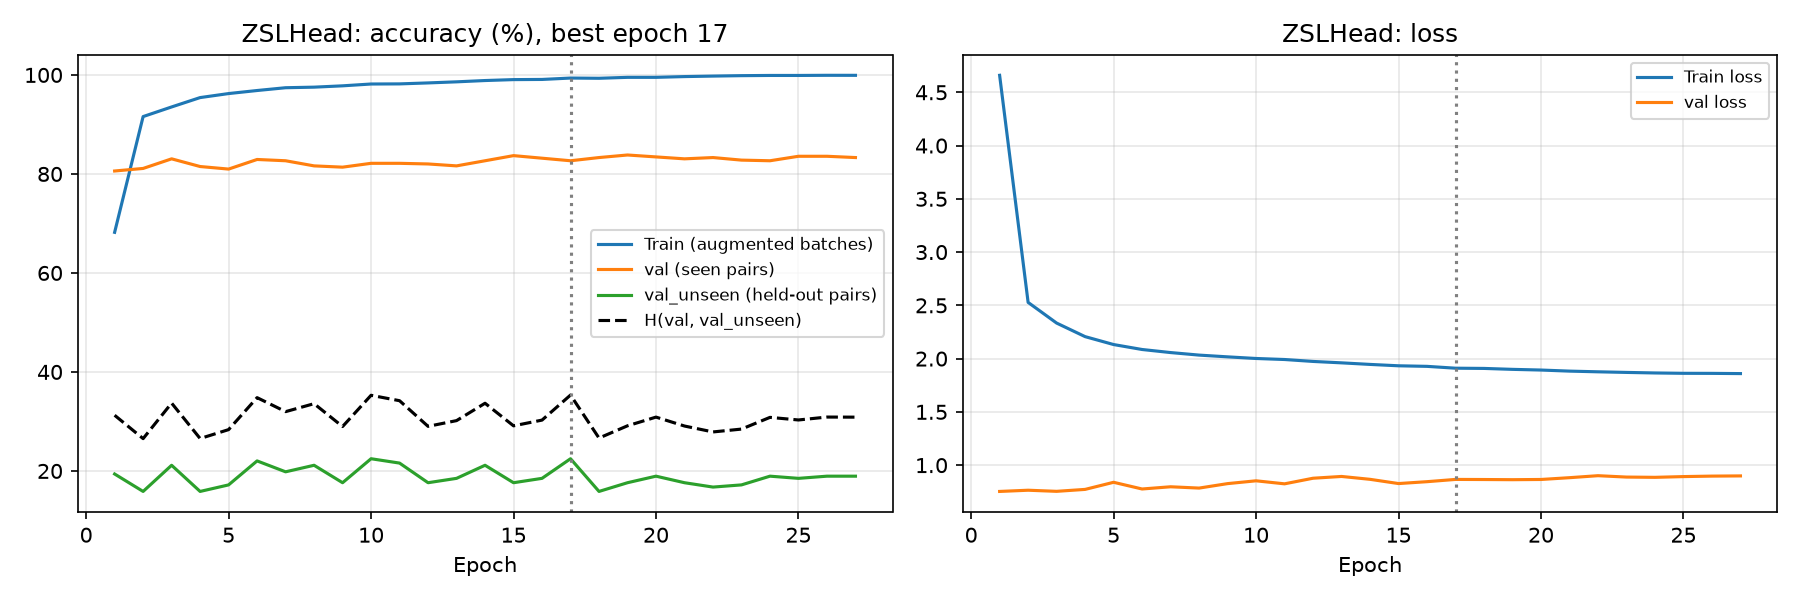

harmonic_mean.png


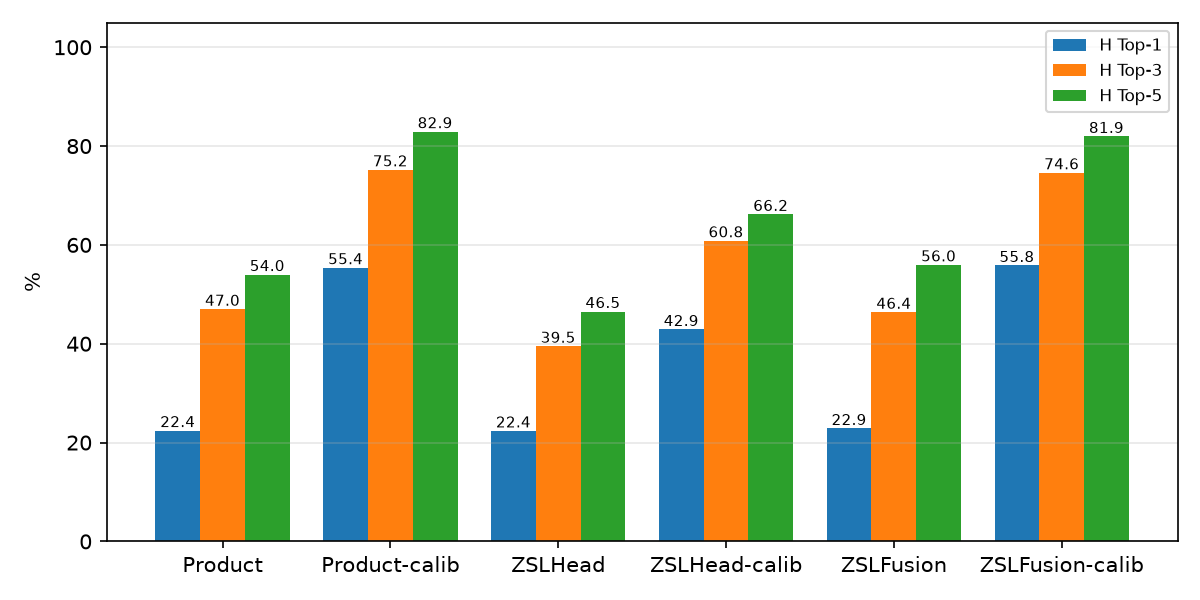

auc_curve.png


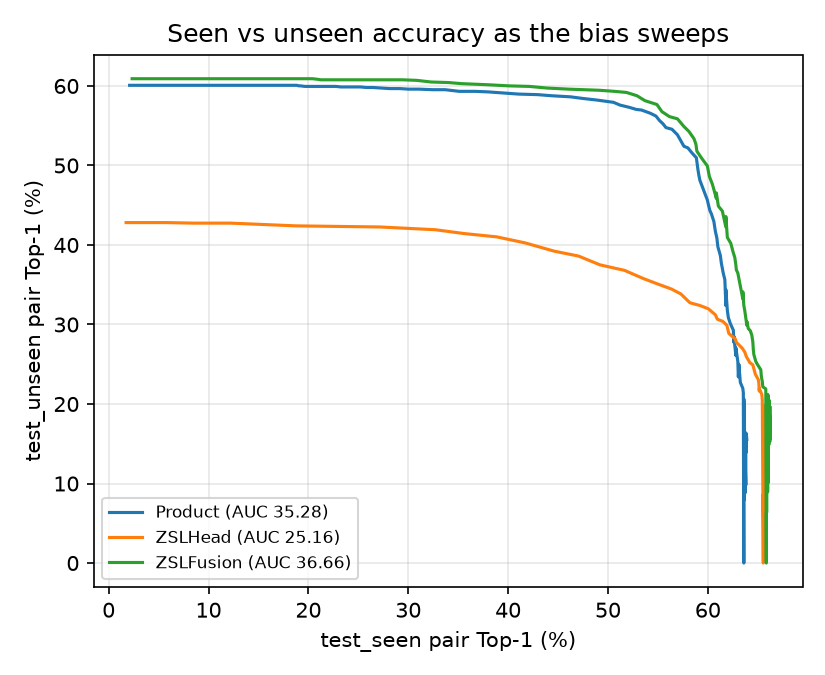

ZSLFusion-calib_unseen_confusion_matrix.png


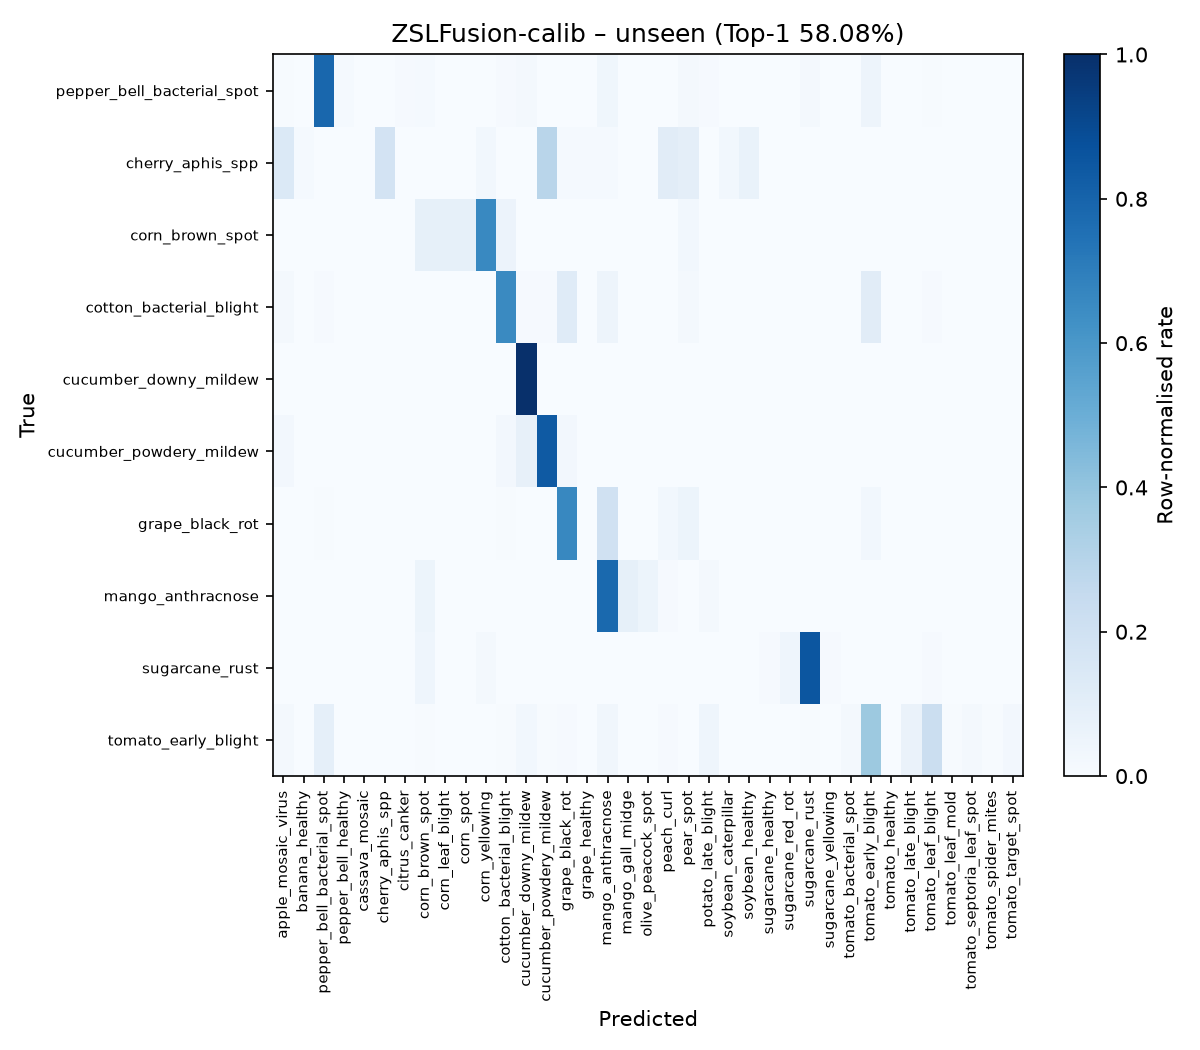

In [13]:
for f in (f"{NAME}_curves.png", "harmonic_mean.png", "auc_curve.png", f"{FUSION}-calib_unseen_confusion_matrix.png"):
    print(f); display(Image(filename=str(OUT / f), width=900))

## 7. Run record

The checksum of the trained ZSLHead, the chosen ZSLFusion weight and bias, and the software environment, so the result can be traced and repeated. The two backbone checksums are stored inside `config.json` and inside `ZSLHead_best.pt`.

**Deterministic mode.** The main run sets `CUBLAS_WORKSPACE_CONFIG=:4096:8`, `torch.backends.cudnn.deterministic = True`, `torch.backends.cudnn.benchmark = False` and `torch.use_deterministic_algorithms(True, warn_only=True)`, so a repeated run on the same machine and software gives the same ZSLHead and the same numbers. The cuBLAS setting is also made in the configuration cell, because cuBLAS reads it when it is first used, which already happens in the pipeline test. With `warn_only=True` an operation without a deterministic version prints a warning instead of stopping the run. The settings are recorded in `config.json`.

In [14]:
pt = OUT / f"{NAME}_best.pt"
print(f"{pt.name} | {pt.stat().st_size / 1e6:.1f} MB | SHA-256 {sha256(pt)}")
print("Platform: local PC | Python", platform.python_version(), "| torch", torch.__version__, "| timm", timm.__version__,
      "| GPU", torch.cuda.get_device_name(0), "| workers", WORKERS)
print("Deterministic mode: CUBLAS_WORKSPACE_CONFIG", os.environ.get("CUBLAS_WORKSPACE_CONFIG"), "| cudnn.deterministic",
      torch.backends.cudnn.deterministic, "| cudnn.benchmark", torch.backends.cudnn.benchmark,
      "| deterministic algorithms", torch.are_deterministic_algorithms_enabled())
print("Dataset: DPD_Small_clean_v2, Kaggle version", KAGGLE_VERSION, "| repo commit", REPO_COMMIT)
print(f"ZSLFusion (val only): w {cal[FUSION]['w']} | bias {cal[FUSION]['bias']:.4f}")
print(f"Result: baseline H {b['harmonic']['1']:.2f} -> ZSLFusion + calibration (ZSLFusion-calib) H {o['harmonic']['1']:.2f}")

ZSLHead_best.pt | 13.3 MB | SHA-256 8951bf7a557b1842bef5a99735684303fc6349baae7a8300d4aa0c6a8292cc4c
Platform: local PC | Python 3.13.15 | torch 2.11.0+cu128 | timm 1.0.31 | GPU NVIDIA GeForce RTX 4060 | workers 0
Deterministic mode: CUBLAS_WORKSPACE_CONFIG :4096:8 | cudnn.deterministic True | cudnn.benchmark False | deterministic algorithms True
Dataset: DPD_Small_clean_v2, Kaggle version <n> | repo commit <hash>
ZSLFusion (val only): w 0.5 | bias 9.3699
Result: baseline H 22.43 -> ZSLFusion + calibration (ZSLFusion-calib) H 55.83


## 8. Ablations

Two ablations isolate the contribution of individual parts. Each uses its own results folder and reuses the cached features.

| Run name | Change | Question it answers |
|---|---|---|
| `step2_no_hal` | `lambda_hal = 0` | How much does feature hallucination (the zero-shot part) add to ZSLHead? |
| `step2_glove` | `pair_emb = "glove"` | Do pretrained GloVe word vectors for crop and disease names help the pair embeddings? |

Each ablation uses its own `RUN_NAME` and the matching value in section 1, and repeats sections 5 to 7, so it also reports all six rows. The GloVe ablation needs the `gensim` package.

## References

- N. Saini, K. Pham and A. Shrivastava, "Disentangling Visual Embeddings for Attributes and Objects", CVPR 2022.
- W.-L. Chao, S. Changpinyo, B. Gong and F. Sha, "An Empirical Study and Analysis of Generalized Zero-Shot Learning for Object Recognition in the Wild", ECCV 2016.
- A. Chai, S. H. Lee et al., "Pairwise Feature Learning for Unseen Plant Disease Recognition", ICIP 2023.
- Z. Liu, H. Mao, C.-Y. Wu, C. Feichtenhofer, T. Darrell and S. Xie, "A ConvNet for the 2020s", CVPR 2022 (ConvNeXt).